# Energy-Conserving \(a_{Q*}\) Scan

This notebook reconstructs the bag constant from \(n_{B,\mathrm{crit}}(T=0)=3n_0\), then solves energy-conserving steady-front profiles for \(m_s=0\), \(T_N=10\ \mathrm{MeV}\), and \(n_B^N=3.2n_0\). The maximum \(a_{Q*}\) is determined by continuing the fixed-\(T_{Q*}\) branch to the exact \(T_{Q*}=0\) endpoint.


In [1]:
import importlib
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter
from IPython.display import display
from scipy.optimize import brentq

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

phase_velocity = importlib.reload(phase_velocity)

# Physical inputs.
n0 = 0.16 * const.MeV_fm**3
T_N = 10.0
nBcrit0_over_n0 = 3.0
metastability_m = 0.2
nBcrit0 = nBcrit0_over_n0 * n0
nB_N = (nBcrit0_over_n0 + metastability_m) * n0
ms = 0.0
NM_type = "PNM"
param = para.paraQMCRMF3

# Solver controls. The endpoint branch is deliberately loose in the BVP
# boundary residual, but energy-flux conservation is checked separately below.
endpoint_tail_eps = 1.0e-4
endpoint_n_mesh = 40
endpoint_tol_bvp = 5.0e-2
endpoint_max_nodes = 5000

profile_tail_eps = 1.0e-5
profile_n_mesh = 40
profile_tol_bvp = 1.0e-4
profile_max_nodes = 5000

jB_bounds = (1.0e-4, 5.0)
endpoint_TQstar_targets = [5.0, 2.0, 1.0, 0.5, 0.2, 0.1, 0.05, 0.02, 0.01, 0.0]
profile_fractions = np.array([0.2, 0.4, 0.6, 0.8, 0.95, 1.0], dtype=float)

print(f"T_N = {T_N:g} MeV")
print(f"nBcrit(T=0) = {nBcrit0_over_n0:g} n0")
print(f"nB_N = {nB_N / n0:g} n0")
print(f"m_s = {ms:g} MeV")


T_N = 10 MeV
nBcrit(T=0) = 3 n0
nB_N = 3.2 n0
m_s = 0 MeV


## Bag Calibration

The bag constant is reconstructed by matching PNM and massless neutral quark matter at \(T=0\) and \(n_B=3n_0\).


In [2]:
def calibration_root(func, x_grid, prefer):
    x_grid = np.asarray(x_grid, dtype=float)
    values = np.full_like(x_grid, np.nan, dtype=float)
    for i, x in enumerate(x_grid):
        try:
            values[i] = float(func(float(x)))
        except Exception:
            values[i] = np.nan

    finite = np.isfinite(values)
    x_grid = x_grid[finite]
    values = values[finite]
    if x_grid.size < 2:
        raise RuntimeError("Not enough finite samples to bracket calibration root")

    exact = np.where(np.isclose(values, 0.0, rtol=0.0, atol=1.0e-8))[0]
    if exact.size:
        hit = exact[np.argmin(np.abs(x_grid[exact] - float(prefer)))]
        return float(x_grid[hit])

    changes = np.where(values[:-1] * values[1:] < 0.0)[0]
    if changes.size == 0:
        raise RuntimeError("No sign change found for calibration root")

    midpoints = 0.5 * (x_grid[changes] + x_grid[changes + 1])
    idx = int(changes[np.argmin(np.abs(midpoints - float(prefer)))])
    return float(brentq(func, float(x_grid[idx]), float(x_grid[idx + 1]), xtol=1.0e-6, rtol=1.0e-8, maxiter=200))


P_crit0 = float(phase_velocity.PNM_n(nBcrit0, 0.0, param=param, NM_type=NM_type))
muB_crit0 = calibration_root(
    lambda mu: phase_velocity.PNM(mu, 0.0, param=param, NM_type=NM_type) - P_crit0,
    np.linspace(900.0, 1500.0, 220),
    prefer=1050.0,
)
B14 = calibration_root(
    lambda B: phase_velocity.PQM(muB_crit0, 0.0, B, 0.0, ms=ms) - P_crit0,
    np.linspace(120.0, 260.0, 281),
    prefer=180.0,
)

P_Q_crit0 = float(phase_velocity.PQM(muB_crit0, 0.0, B14, 0.0, ms=ms))
pressure_match_rel = abs(P_Q_crit0 - P_crit0) / max(abs(P_crit0), 1.0)
if pressure_match_rel > 1.0e-8:
    raise RuntimeError(f"Bag calibration pressure mismatch is too large: {pressure_match_rel:.3e}")

calibration_summary = pd.DataFrame([
    {
        "nBcrit0_over_n0": nBcrit0_over_n0,
        "nB_N_over_n0": nB_N / n0,
        "metastability_m": metastability_m,
        "B14_calibrated_MeV": B14,
        "muB_crit0_MeV": muB_crit0,
        "P_crit0_MeV4": P_crit0,
        "relative_pressure_match": pressure_match_rel,
    }
])
display(calibration_summary)


,nBcrit0_over_n0,nB_N_over_n0,metastability_m,B14_calibrated_MeV,muB_crit0_MeV,P_crit0_MeV4,relative_pressure_match
0,3.0,3.2,0.2,189.156596,1190.93412,6.070174e+08,9.983757e-11


## Exact \(T_{Q*}=0\) Endpoint

The endpoint is found with the core energy-conserving BVP in fixed-\(T_{Q*}\) mode. Each target uses the previous BVP profile as the next initial guess.


In [3]:
def solve_fixed_TQstar(TQstar_target, previous_result=None, jB_guess=0.6, TQ_guess=20.0):
    return phase_velocity._solve_front_energy_conserving_once(
        T=T_N,
        nB_N=nB_N,
        B_one_forth=B14,
        aQstar=None,
        TQstar_target=float(TQstar_target),
        ms=ms,
        param=param,
        NM_type=NM_type,
        tail_eps=endpoint_tail_eps,
        n_mesh=endpoint_n_mesh,
        tol_bvp=endpoint_tol_bvp,
        max_nodes=endpoint_max_nodes,
        jB_guess=float(jB_guess),
        TQ_guess=float(TQ_guess),
        jB_bounds=jB_bounds,
        return_profile=True,
        return_raw_bvp_grid=False,
        verb=False,
        profile_guess=previous_result,
        seed_profile=True,
    )


endpoint_results = []
endpoint_rows = []
previous = None
jB_guess = 0.6
TQ_guess = 20.0

for TQstar_target in endpoint_TQstar_targets:
    result = solve_fixed_TQstar(
        TQstar_target,
        previous_result=previous,
        jB_guess=jB_guess,
        TQ_guess=TQ_guess,
    )
    if not bool(result.get("success")):
        raise RuntimeError(
            f"fixed-TQstar continuation failed at TQstar={TQstar_target:g} MeV: "
            + str(result.get("message", ""))
        )
    endpoint_results.append(result)
    endpoint_rows.append(
        {
            "TQstar_target_MeV": float(TQstar_target),
            "T_Qstar_MeV": float(result["T_Qstar"]),
            "aQstar_derived": float(result["aQstar"]),
            "jB": float(result["jB"]),
            "u_N_m_per_s": float(result["u_N"]) * const.m_per_sec,
            "T_Q_MeV": float(result["T_Q"]),
            "tail_residual_norm": float(result["tail_residual_norm"]),
            "E_right_residual_norm": float(result["E_right_residual_norm"]),
            "kaon_equation_residual_norm": float(result["kaon_equation_residual_norm"]),
            "bvp_nodes": int(result["bvp_nodes"]),
        }
    )
    previous = result
    jB_guess = float(result["jB"])
    TQ_guess = float(result["T_Q"])

endpoint_df = pd.DataFrame(endpoint_rows)
endpoint_result = endpoint_results[-1]
aQstar_max = float(endpoint_result["aQstar"])

if endpoint_result["T_Qstar"] != 0.0:
    raise RuntimeError("Final endpoint did not reach exact T_Qstar = 0")
if not np.isclose(aQstar_max, endpoint_df["aQstar_derived"].max(), rtol=1.0e-10, atol=1.0e-12):
    raise RuntimeError("Exact-zero endpoint is not the maximum derived aQstar on the continued branch")

print(f"aQstar_max from exact T_Qstar=0 endpoint = {aQstar_max:.10f}")
display(endpoint_df)


aQstar_max from exact T_Qstar=0 endpoint = 0.3405983025


,TQstar_target_MeV,T_Qstar_MeV,aQstar_derived,jB,u_N_m_per_s,T_Q_MeV,tail_residual_norm,E_right_residual_norm,kaon_equation_residual_norm,bvp_nodes
0,5.00,5.00,0.330672,0.964838,73.526849,20.648412,-0.022731,4.835520e-12,9.207639e-18,40
1,2.00,2.00,0.339031,1.157501,88.209013,20.648412,-0.007994,-1.275815e-11,1.786412e-18,40
2,1.00,1.00,0.340207,1.262192,96.187144,20.648412,-0.002683,1.201656e-11,1.069301e-17,40
3,0.50,0.50,0.340501,1.341152,102.204360,20.648412,-0.017843,5.290884e-14,0.000000e+00,40
4,0.20,0.20,0.340583,1.422243,108.384018,20.648412,-0.004109,-3.287451e-11,3.578163e-18,40
5,0.10,0.10,0.340594,1.459300,111.208030,20.648412,0.001157,-8.603045e-11,1.792129e-18,40
6,0.05,0.05,0.340597,1.501319,114.410117,20.648412,0.001284,-4.391434e-11,7.187059e-18,40
7,0.02,0.02,0.340598,1.501393,114.415745,20.648412,-0.000175,-4.117160e-11,1.077185e-17,40
8,0.01,0.01,0.340598,1.499097,114.240756,20.648412,0.005377,-4.834557e-11,7.182717e-18,40
9,0.00,0.00,0.340598,1.543499,117.624476,20.648413,-0.009468,5.846395e-11,1.079588e-17,40


## Fixed-\(a_{Q*}\) Profile Solves

The plotted profiles use six fractions of the exact-zero endpoint \(a_{Q*}^{\max}\). The maximum curve reuses the fixed-\(T_{Q*}=0\) endpoint profile.


In [4]:
def solve_fixed_aQstar_profile(aQstar_value, jB_guess=None, TQ_guess=None):
    return phase_velocity.solve_front_energy_conserving(
        T=T_N,
        nB_N=nB_N,
        B_one_forth=B14,
        aQstar=float(aQstar_value),
        ms=ms,
        param=param,
        NM_type=NM_type,
        tail_eps=profile_tail_eps,
        n_mesh=profile_n_mesh,
        tol_bvp=profile_tol_bvp,
        max_nodes=profile_max_nodes,
        jB_guess=jB_guess,
        TQ_guess=TQ_guess,
        jB_bounds=jB_bounds,
        return_profile=True,
        verb=False,
    )


target_aQstar_values = profile_fractions * aQstar_max
profile_results = []
profile_rows = []
last_jB_guess = None
last_TQ_guess = float(endpoint_result["T_Q"])

for fraction, aQstar_value in zip(profile_fractions, target_aQstar_values):
    if np.isclose(fraction, 1.0, rtol=0.0, atol=1.0e-14):
        result = endpoint_result
        solver_source = "fixed_TQstar_endpoint"
    else:
        result = solve_fixed_aQstar_profile(
            aQstar_value,
            jB_guess=last_jB_guess,
            TQ_guess=last_TQ_guess,
        )
        solver_source = "fixed_aQstar"
    if not bool(result.get("success")):
        raise RuntimeError(
            f"profile solve failed for fraction={fraction:g}, aQstar={aQstar_value:.10g}: "
            + str(result.get("message", ""))
        )

    profile_results.append(
        {
            "fraction": float(fraction),
            "aQstar_target": float(aQstar_value),
            "result": result,
            "solver_source": solver_source,
        }
    )
    profile_rows.append(
        {
            "fraction_of_aQstar_max": float(fraction),
            "aQstar": float(result["aQstar"]),
            "solver_source": solver_source,
            "jB": float(result["jB"]),
            "u_N_m_per_s": float(result["u_N"]) * const.m_per_sec,
            "T_Q_MeV": float(result["T_Q"]),
            "T_Qstar_MeV": float(result["T_Qstar"]),
            "tail_residual_norm": float(result["tail_residual_norm"]),
            "E_right_residual_norm": float(result["E_right_residual_norm"]),
            "kaon_equation_residual_norm": float(result["kaon_equation_residual_norm"]),
            "bvp_nodes": int(result["bvp_nodes"]),
            "message": result.get("message", ""),
        }
    )
    last_jB_guess = float(result["jB"])
    last_TQ_guess = float(result["T_Q"])

profile_summary = pd.DataFrame(profile_rows)
display(profile_summary)


,fraction_of_aQstar_max,aQstar,solver_source,jB,u_N_m_per_s,T_Q_MeV,T_Qstar_MeV,tail_residual_norm,E_right_residual_norm,kaon_equation_residual_norm,bvp_nodes,message
0,0.20,0.068120,fixed_aQstar,0.123928,9.444073,20.648412,20.239853,0.000030,-5.086718e-13,6.306366e-18,40,Energy-conserving compact BVP steady-front sol...
1,0.40,0.136239,fixed_aQstar,0.260944,19.885624,20.648412,18.956977,-0.000007,-1.775005e-16,7.150204e-18,40,Energy-conserving compact BVP steady-front sol...
2,0.60,0.204359,fixed_aQstar,0.419798,31.991281,20.648412,16.582785,0.000016,-2.206669e-16,7.247596e-18,40,Energy-conserving compact BVP steady-front sol...
3,0.80,0.272479,fixed_aQstar,0.624496,47.590561,20.648412,12.475285,-0.000077,0.000000e+00,3.451391e-18,40,Energy-conserving compact BVP steady-front sol...
4,0.95,0.323568,fixed_aQstar,0.890262,67.843670,20.648412,6.511339,0.000065,-4.162168e-16,1.138829e-22,41,Energy-conserving compact BVP steady-front sol...
5,1.00,0.340598,fixed_TQstar_endpoint,1.543499,117.624476,20.648413,0.000000,-0.009468,5.846395e-11,1.079588e-17,40,Energy-conserving compact BVP steady-front sol...


## Conservation and Profile Validation


In [5]:
def validate_profile(entry):
    result = entry["result"]
    x = np.asarray(result["x"], dtype=float)
    a = np.asarray(result["a"], dtype=float)
    u = np.asarray(result["u"], dtype=float)
    T_profile = np.asarray(result["T_profile"], dtype=float)
    h_profile = np.asarray(result["h_profile"], dtype=float)
    r_gamma_profile = np.asarray(result["r_gamma_profile"], dtype=float)
    E_profile = h_profile * u * r_gamma_profile
    E_scalar = float(result["E"])
    E_scale = max(abs(E_scalar), 1.0)
    E_relative_range = float(np.ptp(E_profile) / E_scale)
    E_relative_match = float(np.max(np.abs(E_profile - E_scalar)) / E_scale)

    if not np.all(np.isfinite(x)) or not np.all(np.diff(x) > 0.0):
        raise RuntimeError(f"profile grid is not finite and strictly increasing for aQstar={result['aQstar']}")
    if not np.all(np.isfinite(a)) or not np.all(np.isfinite(u)):
        raise RuntimeError(f"profile contains non-finite a or u for aQstar={result['aQstar']}")
    if E_relative_range > 1.0e-6 or E_relative_match > 1.0e-6:
        raise RuntimeError(
            f"energy flux conservation failed for aQstar={result['aQstar']}: "
            f"range={E_relative_range:.3e}, match={E_relative_match:.3e}"
        )

    if entry["solver_source"] == "fixed_TQstar_endpoint":
        if float(result["T_Qstar"]) != 0.0:
            raise RuntimeError("endpoint profile is not exact T_Qstar=0")
        if not np.isclose(T_profile[0], 0.0, rtol=0.0, atol=1.0e-14):
            raise RuntimeError("endpoint profile does not start at T=0")
        if not np.all(np.isfinite(T_profile[1:])) or np.any(T_profile[1:] <= 0.0):
            raise RuntimeError("endpoint profile has non-positive non-interface temperatures")
        residual_limit = endpoint_tol_bvp
    else:
        if not np.all(np.isfinite(T_profile)) or np.any(T_profile <= 0.0):
            raise RuntimeError(f"profile has non-positive temperature for aQstar={result['aQstar']}")
        residual_limit = profile_tol_bvp

    for key in ("tail_residual_norm", "E_right_residual_norm", "kaon_equation_residual_norm"):
        value = float(result.get(key, np.inf))
        if not np.isfinite(value) or abs(value) > max(residual_limit, 1.0e-10):
            raise RuntimeError(f"{key}={value:.3e} exceeds limit {residual_limit:.3e} for aQstar={result['aQstar']}")

    return {
        "fraction_of_aQstar_max": entry["fraction"],
        "aQstar": float(result["aQstar"]),
        "E_relative_range": E_relative_range,
        "E_relative_match": E_relative_match,
        "T_min_MeV": float(np.min(T_profile)),
        "T_max_MeV": float(np.max(T_profile)),
        "x_end_nm": float(result["x_end"] * const.MeV_fm / 1.0e6),
    }


validation_summary = pd.DataFrame([validate_profile(entry) for entry in profile_results])
display(validation_summary)


,fraction_of_aQstar_max,aQstar,E_relative_range,E_relative_match,T_min_MeV,T_max_MeV,x_end_nm
0,0.20,0.068120,2.149054e-14,2.092992e-14,20.239853,20.648412,1300.153353
1,0.40,0.136239,2.396257e-14,2.325257e-14,18.956977,20.648412,1352.000976
2,0.60,0.204359,3.905805e-14,3.839605e-14,16.582785,20.648412,1414.499136
3,0.80,0.272479,3.797415e-14,3.708413e-14,12.475285,20.648412,1498.759953
4,0.95,0.323568,3.704329e-14,3.662707e-14,6.511339,20.648412,1614.249940
5,1.00,0.340598,2.030961e-13,1.674462e-13,0.000000,20.648409,1540.227773


## Profile Overlay


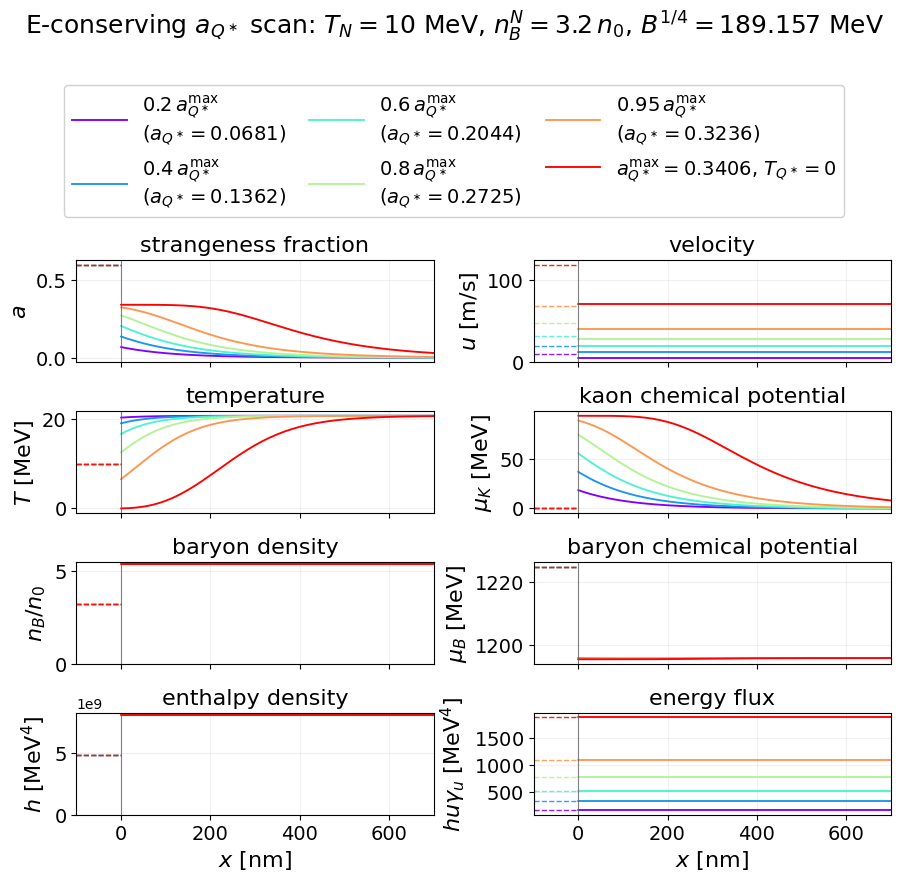

In [13]:
TitleFont = 18
AxisTitleFont = 16
LabelFont = 16
TickFont = 14
LegendFont = 14
LineWidth = 1.35
UpstreamLineWidth = 1.0
ReferenceLineWidth = 0.8
ProfileFigsize = (9.0, 8.8)
x_min_plot = -100.0
x_max_plot = 700.0
upstream_points = 120

P_N_plot = float(phase_velocity.PNM_n(nB_N, T_N, param=param, NM_type=NM_type))
e_N_plot = float(phase_velocity.edensNM_n(nB_N, T_N, param=param))
h_N_plot = P_N_plot + e_N_plot
muB_N_plot = float(
    phase_velocity._solve_scalar_root(
        lambda muB: phase_velocity.nB_NM(muB, T_N, param=param, NM_type=NM_type) - nB_N,
        1050.0,
    )
)
x_upstream_nm = np.linspace(x_min_plot, 0.0, upstream_points)


def make_plot_profile(entry, color):
    result = entry["result"]
    x_nm = np.asarray(result["x"], dtype=float) * const.MeV_fm / 1.0e6
    u_values = np.asarray(result["u"], dtype=float)
    h_values = np.asarray(result["h_profile"], dtype=float)
    r_gamma_values = np.asarray(result["r_gamma_profile"], dtype=float)
    label = (
        rf"${entry['fraction']:.2g}\,a_{{Q^\ast}}^{{\max}}$"
        + "\n"
        + rf"$(a_{{Q^\ast}}={float(result['aQstar']):.4f})$"
    )
    if entry["solver_source"] == "fixed_TQstar_endpoint":
        label = rf"$a_{{Q^\ast}}^{{\max}}={float(result['aQstar']):.4f}$, $T_{{Q^\ast}}=0$"
    return {
        "entry": entry,
        "result": result,
        "label": label,
        "color": color,
        "x_nm": x_nm,
        "a": np.asarray(result["a"], dtype=float),
        "u_m_per_s": u_values * const.m_per_sec,
        "T": np.asarray(result["T_profile"], dtype=float),
        "muK": np.asarray(result["muK"], dtype=float),
        "muB": np.asarray(result["muB"], dtype=float),
        "nB_over_n0": np.asarray(result["nB"], dtype=float) / n0,
        "h": h_values,
        "E_reconstructed": h_values * u_values * r_gamma_values,
    }


colors = plt.get_cmap("rainbow")(np.linspace(0.0, 1.0, len(profile_results)))
plot_profiles = [make_plot_profile(entry, color) for entry, color in zip(profile_results, colors)]


def upstream_value(result, key):
    u_N = float(result["u_N"])
    if key == "a":
        return float(result["a_N"])
    if key == "u_m_per_s":
        return u_N * const.m_per_sec
    if key == "T":
        return T_N
    if key == "muK":
        return float(result.get("muK_N", 0.0))
    if key == "muB":
        return muB_N_plot
    if key == "nB_over_n0":
        return float(nB_N / n0)
    if key == "h":
        return h_N_plot
    if key == "E_reconstructed":
        return float(result["E_N"])
    raise KeyError(key)


plot_specs = [
    ("a", r"$a$", "strangeness fraction"),
    ("u_m_per_s", r"$u$ [m/s]", "velocity"),
    ("T", r"$T$ [MeV]", "temperature"),
    ("muK", r"$\mu_K$ [MeV]", "kaon chemical potential"),
    ("nB_over_n0", r"$n_B/n_0$", "baryon density"),
    ("muB", r"$\mu_B$ [MeV]", "baryon chemical potential"),
    ("h", r"$h$ [MeV$^4$]", "enthalpy density"),
    ("E_reconstructed", r"$h u \gamma_u$ [MeV$^4$]", "energy flux"),
]
zero_floor_keys = {"u_m_per_s", "nB_over_n0", "h"}

fig, axes = plt.subplots(4, 2, figsize=ProfileFigsize, sharex=True)
fig.subplots_adjust(left=0.08, right=0.985, bottom=0.07, top=0.70, hspace=0.48, wspace=0.28)
axes = axes.ravel()

for ax, (key, ylabel, title) in zip(axes, plot_specs):
    for profile in plot_profiles:
        ax.plot(profile["x_nm"], profile[key], color=profile["color"], lw=LineWidth, solid_capstyle="round")
        y_left = upstream_value(profile["result"], key)
        ax.plot(
            x_upstream_nm,
            np.full_like(x_upstream_nm, y_left, dtype=float),
            color=profile["color"],
            lw=UpstreamLineWidth,
            ls="--",
            alpha=0.9,
        )
    ax.axvline(0.0, color="0.35", lw=ReferenceLineWidth, alpha=0.75)
    ax.set_xlim(x_min_plot, x_max_plot)
    ax.set_title(title, fontsize=AxisTitleFont, pad=6)
    ax.set_ylabel(ylabel, fontsize=LabelFont)
    ax.tick_params(labelsize=TickFont)
    ax.grid(True, alpha=0.18, linewidth=0.8)
    if key in zero_floor_keys:
        ymin, ymax = ax.get_ylim()
        ax.set_ylim(0.0, ymax if ymax > 0.0 else 1.0)
    if key == "E_reconstructed":
        formatter = ScalarFormatter(useMathText=True)
        formatter.set_powerlimits((-3, 4))
        ax.yaxis.set_major_formatter(formatter)

for ax in axes[-2:]:
    ax.set_xlabel(r"$x$ [nm]", fontsize=LabelFont)

legend_handles = [Line2D([0], [0], color=p["color"], lw=LineWidth, label=p["label"]) for p in plot_profiles]
fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.91),
    ncol=3,
    fontsize=LegendFont,
    frameon=True,
    framealpha=0.92,
    handlelength=2.8,
    columnspacing=1.2,
)
fig.suptitle(
    rf"E-conserving $a_{{Q^\ast}}$ scan: $T_N={T_N:g}$ MeV, "
    rf"$n_B^N={nB_N / n0:.1f}\,n_0$, $B^{{1/4}}={B14:.3f}$ MeV",
    fontsize=TitleFont,
    y=0.985,
)

plt.savefig("/Users/janshao/NSM_related/local_analysis_results/26SU-6/aQstar_scan.pdf", dpi=240, facecolor="white")

plt.show()


## Endpoint Diagnostic


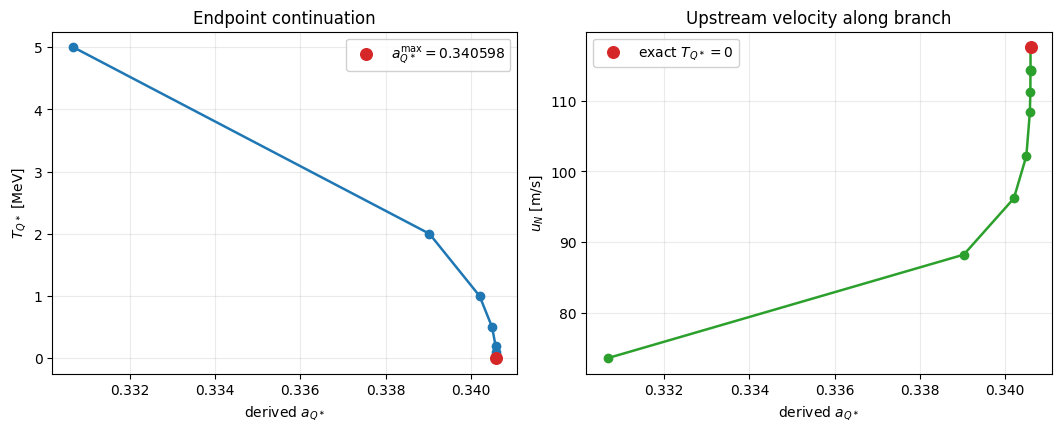

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), constrained_layout=True)

axes[0].plot(endpoint_df["aQstar_derived"], endpoint_df["T_Qstar_MeV"], marker="o", lw=1.8, color="C0")
axes[0].scatter([aQstar_max], [0.0], s=70, color="C3", zorder=4, label=rf"$a_{{Q^\ast}}^{{\max}}={aQstar_max:.6f}$")
axes[0].set_xlabel(r"derived $a_{Q^\ast}$")
axes[0].set_ylabel(r"$T_{Q^\ast}$ [MeV]")
axes[0].set_title(r"Endpoint continuation")
axes[0].grid(alpha=0.25)
axes[0].legend(framealpha=0.9)

axes[1].plot(endpoint_df["aQstar_derived"], endpoint_df["u_N_m_per_s"], marker="o", lw=1.8, color="C2")
axes[1].scatter(
    [aQstar_max],
    [float(endpoint_result["u_N"]) * const.m_per_sec],
    s=70,
    color="C3",
    zorder=4,
    label=r"exact $T_{Q^\ast}=0$",
)
axes[1].set_xlabel(r"derived $a_{Q^\ast}$")
axes[1].set_ylabel(r"$u_N$ [m/s]")
axes[1].set_title(r"Upstream velocity along branch")
axes[1].grid(alpha=0.25)
axes[1].legend(framealpha=0.9)

plt.show()
